# Task 5  GAN


In [1]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


I change the FAST_TRAIN_SAMPLES to 30k in order get better performance 

In [ ]:

SEED = 42
LATENT_DIM = 100
BATCH_SIZE = 256
NUM_EPOCHS = 40 
LEARNING_RATE = 1e-4
BETAS = (0.5, 0.999)
REAL_LABEL = 0.9
FAKE_LABEL = 0.1
FAST_TRAIN_SAMPLES = 30000 


PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def build_subset_indices(dataset_size, subset_size, seed):
    # random pick of indices
    generator = torch.Generator()
    generator.manual_seed(seed)
    permutation = torch.randperm(dataset_size, generator=generator).tolist()
    return permutation[:subset_size]

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(True),
            nn.BatchNorm1d(256), 
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.BatchNorm1d(512),
            nn.Linear(512, 1024),
            nn.ReLU(True),
            nn.BatchNorm1d(1024),
            nn.Linear(1024, 784),
            nn.Tanh(), 
        )

    def forward(self, z):
        return self.main(z).view(-1, 1, 28, 28)

In [5]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
        )

    def forward(self, img):
        img_flat = img.view(img.size(0), -1)
        return self.main(img_flat)

In [6]:


def build_dataloader():
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ])
    full_dataset = datasets.MNIST(
        root=str(DATA_DIR),
        train=True,
        download=True,
        transform=transform,
    )

    # only use small part of the data
    subset_indices = build_subset_indices(
        dataset_size=len(full_dataset),
        subset_size=min(FAST_TRAIN_SAMPLES, len(full_dataset)),
        seed=SEED,
    )
    dataset = Subset(full_dataset, subset_indices)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)


In [ ]:
def train_gan(generator, discriminator, train_loader, device):
    
    # BCEWithLogitsLoss does not change the theoretical loss “sigmoid + BCE”
    # it changes the way its calculated, to avoid numerical problems when the logits are very large or small
    criterion = nn.BCEWithLogitsLoss()   

    optimizer_g = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=BETAS)   
    optimizer_d = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=BETAS)


    history = {  
        "epoch": [],
        "d_loss": [],
        "g_loss": [],
        "d_acc": [],
    }


    for epoch in range(1, NUM_EPOCHS + 1):
        generator.train()  
        discriminator.train()

        total_d_loss = 0.0
        total_g_loss = 0.0   
        total_d_acc = 0.0
        batch_count = 0

        for real_imgs, _ in train_loader:
            real_imgs = real_imgs.to(device)   
            batch_size = real_imgs.size(0)
            
            # soft labels:
            # real images are labeled with REAL_LABEL 0.9 instead of exactly 1
            # fake images are labeled with FAKE_LABEL 0.1 instead of exactly 0
            real_labels = torch.full((batch_size, 1), REAL_LABEL, device=device)  
            fake_labels = torch.full((batch_size, 1), FAKE_LABEL, device=device)

            optimizer_d.zero_grad()     


            real_outputs = discriminator(real_imgs)   # prediction on real images by D
            real_loss = criterion(real_outputs, real_labels)

            #generate a batch of fake images from random noise
            z = torch.randn(batch_size, LATENT_DIM, device=device)   
            fake_imgs = generator(z)
            
            
            # discriminator prediction on fake images
            fake_outputs = discriminator(fake_imgs.detach())  #detach is used so we can use fake images for D, 
                                                            #but do not send gradients back into the generator in this step

            fake_loss = criterion(fake_outputs, fake_labels)

            d_loss = real_loss+fake_loss   # total D loss
            d_loss.backward()
            optimizer_d.step()   

            # Train generator
            
            for p in discriminator.parameters():
                p.requires_grad = False# temporarily freeze discriminator so only generator is updated


            optimizer_g.zero_grad()

            z = torch.randn(batch_size, LATENT_DIM, device=device)#generate a new batch of fake images for the generator step

            fake_imgs = generator(z)   # generate new fake batch
            fake_outputs_for_g = discriminator(fake_imgs)  #pass fake images through the discr.
            
             # the generator wants fake images to be classified as real
            generator_targets = torch.ones((batch_size, 1), device=device)   
            g_loss = criterion(fake_outputs_for_g, generator_targets)

            g_loss.backward()   
            optimizer_g.step()
            for p in discriminator.parameters():
                p.requires_grad = True   # unfreeze Discr. parameters for next iteration

            with torch.no_grad():
                real_correct = (real_outputs > 0).float().mean()   
                fake_correct = (fake_outputs < 0).float().mean()
                d_acc = (real_correct + fake_correct) / 2.0   #final discriminator accuracy = average of the 2

            total_d_loss += d_loss.item()
            total_g_loss += g_loss.item()
            total_d_acc += d_acc.item()
            batch_count += 1   

        avg_d_loss = total_d_loss / batch_count
        avg_g_loss = total_g_loss / batch_count
        avg_d_acc = total_d_acc / batch_count   

        history["epoch"].append(epoch)
        history["d_loss"].append(avg_d_loss)
        history["g_loss"].append(avg_g_loss)
        history["d_acc"].append(avg_d_acc)   

        print(f"Epoch [{epoch}/{NUM_EPOCHS}]  ,  "f"D Loss: {avg_d_loss:.4f}  ,  "f"G Loss: {avg_g_loss:.4f}  ,  "
            f"D Acc: {avg_d_acc:.4f}")   

    return history  

In [8]:

def plot_training_curves(history):
    epochs = history["epoch"]

    plt.figure(figsize=(15, 6))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["d_loss"], label="Discriminator Loss")
    plt.plot(epochs, history["g_loss"], label="Generator Loss")
    plt.title("GAN Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["d_acc"], label="Discriminator Accuracy", color="green")
    plt.axhline(y=0.5, color="red", linestyle="--", label="Random Guess (0.5)")
    plt.title("Discriminator Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()


def sample_noise(num_samples, seed, device):
    torch.manual_seed(seed)
    return torch.randn(num_samples, LATENT_DIM, device=device)




Epoch [1/40]  ,  D Loss: 0.8529  ,  G Loss: 1.1066  ,  D Acc: 0.9495
Epoch [2/40]  ,  D Loss: 0.7751  ,  G Loss: 1.4944  ,  D Acc: 0.9812
Epoch [3/40]  ,  D Loss: 0.9744  ,  G Loss: 1.3177  ,  D Acc: 0.8554
Epoch [4/40]  ,  D Loss: 0.9301  ,  G Loss: 1.4736  ,  D Acc: 0.9090
Epoch [5/40]  ,  D Loss: 1.0432  ,  G Loss: 1.2552  ,  D Acc: 0.8299
Epoch [6/40]  ,  D Loss: 1.1724  ,  G Loss: 0.9454  ,  D Acc: 0.7507
Epoch [7/40]  ,  D Loss: 1.1899  ,  G Loss: 0.9220  ,  D Acc: 0.7375
Epoch [8/40]  ,  D Loss: 1.1883  ,  G Loss: 0.9368  ,  D Acc: 0.7415
Epoch [9/40]  ,  D Loss: 1.1767  ,  G Loss: 0.9944  ,  D Acc: 0.7534
Epoch [10/40]  ,  D Loss: 1.2126  ,  G Loss: 0.9673  ,  D Acc: 0.7249
Epoch [11/40]  ,  D Loss: 1.2323  ,  G Loss: 0.9296  ,  D Acc: 0.7100
Epoch [12/40]  ,  D Loss: 1.2277  ,  G Loss: 0.9390  ,  D Acc: 0.7149
Epoch [13/40]  ,  D Loss: 1.2661  ,  G Loss: 0.8869  ,  D Acc: 0.6848
Epoch [14/40]  ,  D Loss: 1.2879  ,  G Loss: 0.8358  ,  D Acc: 0.6631
Epoch [15/40]  ,  D Loss: 1.2

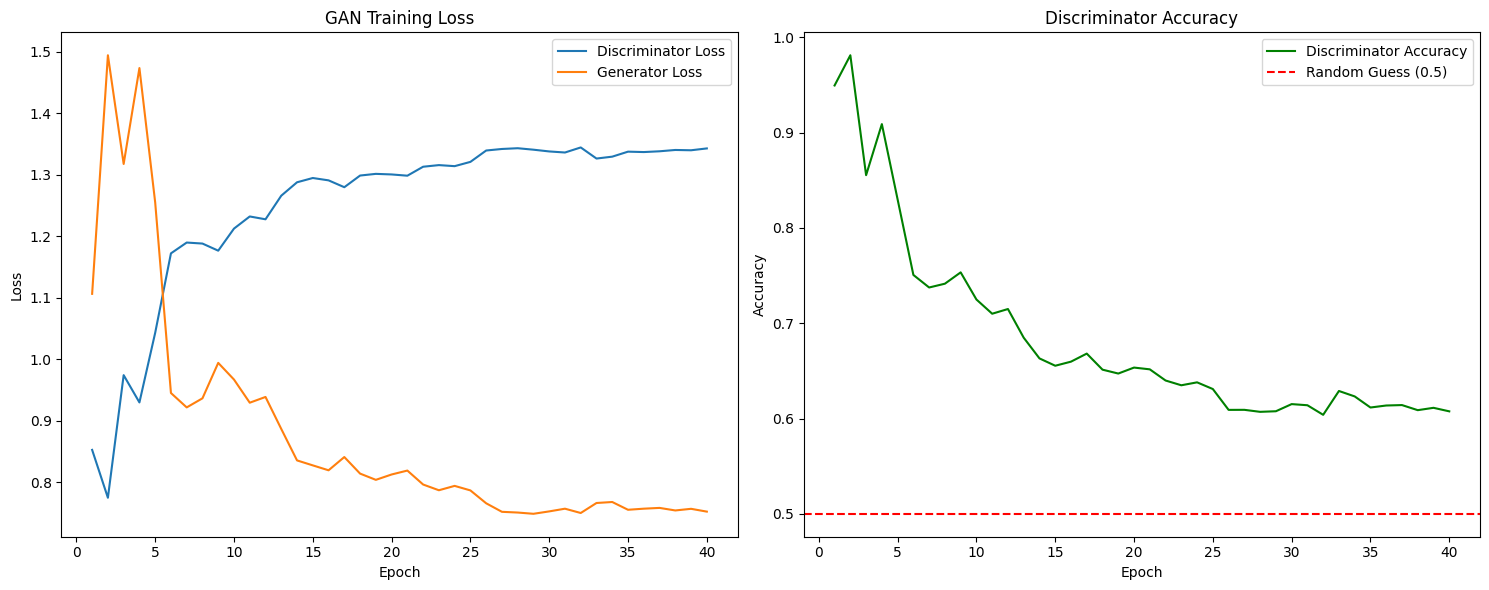

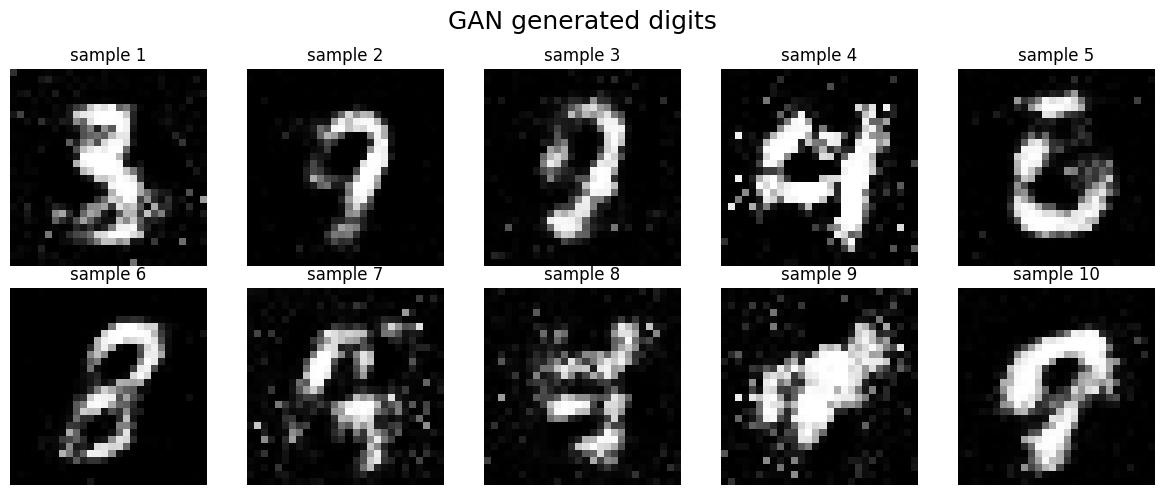

Final D loss: 1.3429
Final G loss: 0.7526
Final D accuracy: 0.6075


In [10]:
# Actual execution of the training
set_seed(SEED)
generator = Generator(LATENT_DIM).to(device)
discriminator = Discriminator().to(device)

train_loader = build_dataloader()



history = train_gan(generator, discriminator, train_loader, device)

plot_training_curves(history)
generator.eval()
with torch.no_grad():
    z = sample_noise(num_samples=10, seed=SEED, device=device)
    generated_samples = (generator(z).cpu() + 1) / 2.0


fig, axes = plt.subplots(2, 5, figsize=(12, 5))



for index, ax in enumerate(axes.flat):
    ax.imshow(generated_samples[index].squeeze(), cmap="gray")
    ax.set_title(f"sample {index + 1}")
    ax.axis("off")

plt.suptitle("GAN generated digits", fontsize=18)
plt.tight_layout()
plt.show()


print(f"Final D loss: {history['d_loss'][-1]:.4f}")
print(f"Final G loss: {history['g_loss'][-1]:.4f}")
print(f"Final D accuracy: {history['d_acc'][-1]:.4f}")

From the plots we can see the Generator loss goes down (while fluctating) respect to the previous experiment but it doesn't stay perfectly stable. It is ok considering the model is trained for only 40 epochs and uses only part of the dataset.
Final Discriminator accuracy: 0.6075, which is lower than the previous one(65%), this is coherent with the generator loss that goes down and the discriminator loss that becomes to stay more stable. 

previous experiment:

Final D loss: 1.3027
Final G loss: 0.8215 

so the higher value of discr. loss is totally coherent with the lower final accuracy. this is a the consequence of a lower final gen loss which drops to 0.75


so we can conclude we get better results than before and the amomut of available data was a key factor to get a winning training.
anyway the generated images are still not fully convincing, so same conclusions of last experiment


In the next experiment I will change the number of epochs to 60